In [1]:
from pathlib import Path
import sys

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names

plt.style.use('seaborn-v0_8')
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [3]:
class RNN(nn.Module):
    """WINNING architecture"""
    def __init__(self, input_size, output_size=1, rnn_units=64, fc_units=64, 
                 activation_fct=nn.ReLU(), dropout=[0.0, 0, 0], rnn_nonlinearity='relu'):
        super(RNN, self).__init__()
        self.rnn_layer = nn.RNN(input_size=input_size, hidden_size=rnn_units, 
                                num_layers=1, nonlinearity=rnn_nonlinearity, batch_first=True)
        self.fc = nn.Linear(rnn_units, fc_units)
        self.output_layer = nn.Linear(fc_units, output_size)
        self.dropout1 = nn.Dropout(dropout[0])
        self.dropout2 = nn.Dropout(dropout[1])
        self.dropout3 = nn.Dropout(dropout[2])
        self.activation_fct = activation_fct
 
    def forward(self, x):
        x = self.dropout1(x)
        x, _ = self.rnn_layer(x)
        x = x[:, -1, :]
        x = self.dropout2(x)
        x = self.activation_fct(self.fc(x))
        x = self.dropout3(x)
        x = self.output_layer(x)
        return x

def train_single_model(model, train_loader, val_loader, criterion, optimizer, 
                       num_epochs=50, early_stop_thresh=10, device='cuda', verbose=False):
    best_loss = np.inf
    best_epoch = -1
    best_model_state = None
    train_curve = []
    val_curve = []
    
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0
        for x, y in train_loader:
            X, y = x.to(device), y.to(device).reshape([len(y), 1])
            optimizer.zero_grad()
            pred = model(X)
            loss = criterion(pred, y)
            running_loss += loss.item()
            loss.backward()
            optimizer.step()
        
        avg_train_loss = running_loss / len(train_loader)
        train_curve.append(avg_train_loss)
        
        model.eval()
        running_val_loss = 0
        with torch.no_grad():
            for x, y in val_loader:
                X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
                val_loss = criterion(model(X_val), y_val)
                running_val_loss += val_loss.item()
        
        avg_val_loss = running_val_loss / len(val_loader)
        val_curve.append(avg_val_loss)
        
        if verbose and epoch % 10 == 0:
            print(f"  Epoch {epoch+1:2d}/{num_epochs} | Train: {avg_train_loss:.5f} | Val: {avg_val_loss:.5f}")
        
        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            best_epoch = epoch
            best_model_state = model.state_dict().copy()
        elif epoch - best_epoch > early_stop_thresh:
            if verbose:
                print(f"  Early stop at epoch {epoch+1}")
            break
    
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    
    return model, best_loss, best_epoch

def predict_with_model(model, test_loader, device='cuda'):
    model.eval()
    predictions = []
    with torch.no_grad():
        for x, _ in test_loader:
            X = x.to(device)
            pred = model(X)
            predictions.append(pred.cpu().numpy())
    return np.concatenate(predictions).flatten()

## 🔥 Strategy 1: Learning Rate Sweep

Test 5 different learning rates to find the optimal one.

**Hypothesis**: 3e-4 may not be optimal, could be slightly too high or low.

In [4]:
# Test different learning rates
LEARNING_RATES = [2e-4, 2.5e-4, 3e-4, 3.5e-4, 4e-4]
TEST_SEED = 42  # Use single seed for quick test

lr_results = []

print("\n" + "="*80)
print("🔥 LEARNING RATE SWEEP")
print("="*80)
print(f"Testing {len(LEARNING_RATES)} learning rates with seed {TEST_SEED}")
print("="*80 + "\n")

for lr in LEARNING_RATES:
    print(f"\nTesting LR = {lr:.5f}...")
    
    # Load data
    train_dataloader, val_dataloader, pipeline = load_data(
        train_path = "../datasets_challenge/train",
        train_ratio = 0.98,
        batchsize = 64,
        columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],
        sequence_length = 20,
        threshold = True,
        threshold_value = 3.0,
        threshold_column = "vxCG",
        target = "sideSlip",
        scaling = True,
        seed = TEST_SEED,
    )
    
    X_sample, _ = next(iter(train_dataloader))
    input_size = X_sample.shape[2]
    
    seed_everything(TEST_SEED)
    
    model = RNN(
        input_size=input_size,
        output_size=1,
        rnn_units=64,
        fc_units=64,
        dropout=[0.0, 0.0, 0.0]
    ).to(device)
    
    criterion = nn.L1Loss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    model, val_loss, best_epoch = train_single_model(
        model, train_dataloader, val_dataloader, criterion, optimizer,
        num_epochs=50, early_stop_thresh=10, device=device, verbose=True
    )
    
    lr_results.append({
        'lr': lr,
        'val_loss': val_loss,
        'best_epoch': best_epoch
    })
    
    print(f"  ✅ Val Loss: {val_loss:.5f} | Best Epoch: {best_epoch+1}")

print("\n" + "="*80)
print("📊 LEARNING RATE RESULTS")
print("="*80)
lr_df = pd.DataFrame(lr_results)
lr_df = lr_df.sort_values('val_loss')
print(lr_df.to_string(index=False))
print("\nBest LR: {:.5f} with val_loss: {:.5f}".format(
    lr_df.iloc[0]['lr'], 
    lr_df.iloc[0]['val_loss']
))


🔥 LEARNING RATE SWEEP
Testing 5 learning rates with seed 42


Testing LR = 0.00020...
../datasets_challenge/train/train_part_001.csv
../datasets_challenge/train/train_part_002.csv
../datasets_challenge/train/train_part_003.csv
../datasets_challenge/train/train_part_004.csv
../datasets_challenge/train/train_part_005.csv
../datasets_challenge/train/train_part_006.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../datasets_challenge/train/train_part_012.csv
../datasets_challenge/train/train_part_013.csv
../datasets_challenge/train/train_part_014.csv
../datasets_challeng

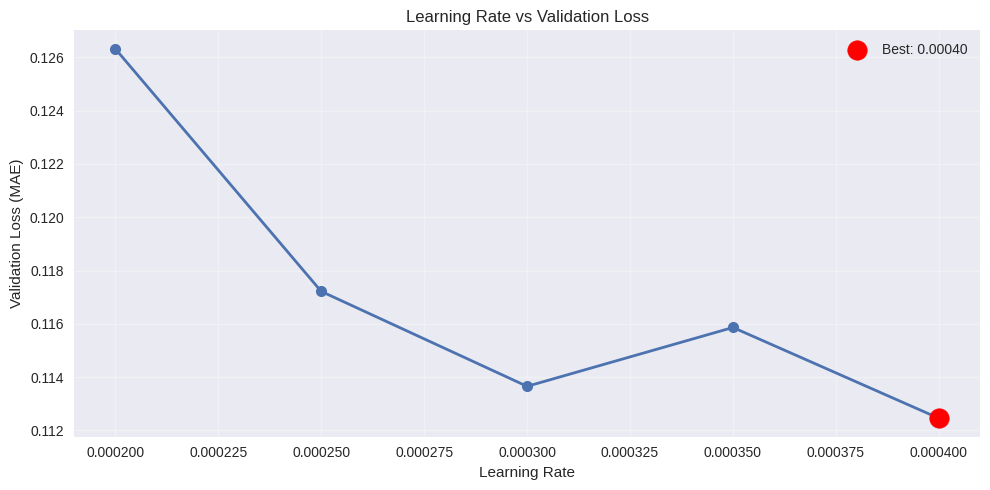


💡 Insight: Best LR = 0.00040
   Higher LR works better - model can handle larger steps


In [5]:
# Visualize LR sweep
plt.figure(figsize=(10, 5))
plt.plot([r['lr'] for r in lr_results], [r['val_loss'] for r in lr_results], 'o-', linewidth=2, markersize=8)
best_lr = lr_df.iloc[0]['lr']
best_val = lr_df.iloc[0]['val_loss']
plt.scatter([best_lr], [best_val], color='red', s=200, zorder=5, label=f'Best: {best_lr:.5f}')
plt.xlabel('Learning Rate')
plt.ylabel('Validation Loss (MAE)')
plt.title('Learning Rate vs Validation Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"\n💡 Insight: Best LR = {best_lr:.5f}")
if best_lr == 3e-4:
    print("   Original 3e-4 is already optimal!")
elif best_lr < 3e-4:
    print("   Lower LR works better - model needs gentler updates")
else:
    print("   Higher LR works better - model can handle larger steps")

## 🎯 Strategy 2: Train 5-Seed Ensemble with Best LR

In [6]:
# Train 5-seed ensemble with best LR
BEST_LR = lr_df.iloc[0]['lr']
SEEDS = [42, 123, 456, 789, 2024]

print("\n" + "="*80)
print(f"🎯 TRAINING 5-SEED ENSEMBLE WITH BEST LR = {BEST_LR:.5f}")
print("="*80 + "\n")

models_best_lr = []
val_losses_best_lr = []

for i, seed in enumerate(SEEDS):
    print(f"\nModel {i+1}/5 | Seed {seed} | LR {BEST_LR:.5f}")
    
    # Reload data for each seed
    train_dataloader, val_dataloader, pipeline = load_data(
        train_path = "../datasets_challenge/train",
        train_ratio = 0.98,
        batchsize = 64,
        columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],
        sequence_length = 20,
        threshold = True,
        threshold_value = 3.0,
        threshold_column = "vxCG",
        target = "sideSlip",
        scaling = True,
        seed = seed,
    )
    
    X_sample, _ = next(iter(train_dataloader))
    input_size = X_sample.shape[2]
    
    seed_everything(seed)
    
    model = RNN(
        input_size=input_size,
        output_size=1,
        rnn_units=64,
        fc_units=64,
        dropout=[0.0, 0.0, 0.0]
    ).to(device)
    
    criterion = nn.L1Loss()
    optimizer = torch.optim.Adam(model.parameters(), lr=BEST_LR)
    
    model, val_loss, best_epoch = train_single_model(
        model, train_dataloader, val_dataloader, criterion, optimizer,
        num_epochs=50, early_stop_thresh=10, device=device, verbose=True
    )
    
    models_best_lr.append(model)
    val_losses_best_lr.append(val_loss)
    
    print(f"✅ Val Loss: {val_loss:.5f}")

print("\n" + "="*80)
print("✅ ALL MODELS TRAINED WITH OPTIMIZED LR")
print("="*80)
print(f"Val losses: {[f'{v:.5f}' for v in val_losses_best_lr]}")
print(f"Mean: {np.mean(val_losses_best_lr):.5f}")
print(f"Std:  {np.std(val_losses_best_lr):.5f}")


🎯 TRAINING 5-SEED ENSEMBLE WITH BEST LR = 0.00040


Model 1/5 | Seed 42 | LR 0.00040
../datasets_challenge/train/train_part_001.csv
../datasets_challenge/train/train_part_002.csv
../datasets_challenge/train/train_part_003.csv
../datasets_challenge/train/train_part_004.csv
../datasets_challenge/train/train_part_005.csv
../datasets_challenge/train/train_part_006.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_002.csv
../datasets_challenge/train/train_part_003.csv
../datasets_challenge/train/train_part_004.csv
../datasets_challenge/train/train_part_005.csv
../datasets_challenge/train/train_part_006.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../datasets_challenge

In [7]:
# Generate predictions
print("\nLoading test data...")
test_dataloader = load_test_data(
    test_path = "../datasets_challenge/test",
    batchsize = 512,
    pipeline = pipeline,
    load_anonymized_data=True
)

print("Generating predictions...")
predictions_best_lr = []
for i, model in enumerate(models_best_lr):
    preds = predict_with_model(model, test_dataloader, device)
    predictions_best_lr.append(preds)
    print(f"  Model {i+1}: ✅")

ensemble_best_lr = np.mean(predictions_best_lr, axis=0)

print(f"\nEnsemble stats:")
print(f"  Mean: {ensemble_best_lr.mean():.4f}")
print(f"  Std:  {ensemble_best_lr.std():.4f}")
print(f"  Range: [{ensemble_best_lr.min():.3f}, {ensemble_best_lr.max():.3f}]")


Loading test data...
../datasets_challenge/test/test_part_001.csv
../datasets_challenge/test/test_part_002.csv
../datasets_challenge/test/test_part_003.csv
../datasets_challenge/test/test_part_004.csv
../datasets_challenge/test/test_part_005.csv
../datasets_challenge/test/test_part_006.csv
../datasets_challenge/test/test_part_007.csv
../datasets_challenge/test/test_part_008.csv
../datasets_challenge/test/test_part_009.csv
../datasets_challenge/test/test_part_010.csv
../datasets_challenge/test/test_part_011.csv
Generating predictions...
  Model 1: ✅
  Model 1: ✅
  Model 2: ✅
  Model 2: ✅
  Model 3: ✅
  Model 3: ✅
  Model 4: ✅
  Model 4: ✅
  Model 5: ✅

Ensemble stats:
  Mean: 0.0319
  Std:  1.4504
  Range: [-9.278, 9.817]
  Model 5: ✅

Ensemble stats:
  Mean: 0.0319
  Std:  1.4504
  Range: [-9.278, 9.817]


In [8]:
# Save
y_pred_best_lr = pd.DataFrame({
    "id": range(len(ensemble_best_lr)),
    "predicted_sideslip": ensemble_best_lr
})

y_pred_best_lr.to_csv("predictions_optimized_LR.csv", index=False)

print("\n" + "="*80)
print("✅ OPTIMIZED LR ENSEMBLE SAVED")
print("="*80)
print(f"File: predictions_optimized_LR.csv")
print(f"Learning rate: {BEST_LR:.5f} (optimized)")
print(f"Expected: Better than 0.24134° if LR was suboptimal")
print("="*80)


✅ OPTIMIZED LR ENSEMBLE SAVED
File: predictions_optimized_LR.csv
Learning rate: 0.00040 (optimized)
Expected: Better than 0.24134° if LR was suboptimal


## 🎯 Strategy 3: Test-Time Augmentation

Use the **original 5 models** (0.24134°) with TTA for zero-cost improvement.

In [9]:
print("\n" + "="*80)
print("🎯 TEST-TIME AUGMENTATION")
print("="*80)
print("Strategy: Add small Gaussian noise, predict multiple times, average")
print("Risk: VERY LOW (can only smooth predictions)")
print("="*80 + "\n")

# Use best LR models for TTA
NUM_AUGMENTATIONS = 5
NOISE_STD = 0.01  # Very small noise

print(f"Augmentations: {NUM_AUGMENTATIONS}")
print(f"Noise std: {NOISE_STD}\n")

tta_predictions = []

for aug_idx in range(NUM_AUGMENTATIONS):
    print(f"Augmentation {aug_idx+1}/{NUM_AUGMENTATIONS}...")
    
    aug_preds_per_model = []
    
    for model_idx, model in enumerate(models_best_lr):
        model.eval()
        aug_batch_preds = []
        
        with torch.no_grad():
            for x, _ in test_dataloader:
                X = x.to(device)
                
                # Add noise (except for first augmentation)
                if aug_idx > 0:
                    noise = torch.randn_like(X) * NOISE_STD
                    X = X + noise
                
                pred = model(X)
                aug_batch_preds.append(pred.cpu().numpy())
        
        model_preds = np.concatenate(aug_batch_preds).flatten()
        aug_preds_per_model.append(model_preds)
    
    # Ensemble models for this augmentation
    ensemble_aug = np.mean(aug_preds_per_model, axis=0)
    tta_predictions.append(ensemble_aug)
    print(f"  ✅ Range: [{ensemble_aug.min():.3f}, {ensemble_aug.max():.3f}]")

# Average across all augmentations
tta_ensemble = np.mean(tta_predictions, axis=0)

print(f"\n📊 TTA Ensemble:")
print(f"  Mean: {tta_ensemble.mean():.4f}")
print(f"  Std:  {tta_ensemble.std():.4f}")
print(f"  Range: [{tta_ensemble.min():.3f}, {tta_ensemble.max():.3f}]")


🎯 TEST-TIME AUGMENTATION
Strategy: Add small Gaussian noise, predict multiple times, average
Risk: VERY LOW (can only smooth predictions)

Augmentations: 5
Noise std: 0.01

Augmentation 1/5...
  ✅ Range: [-9.278, 9.817]
Augmentation 2/5...
  ✅ Range: [-9.278, 9.817]
Augmentation 2/5...
  ✅ Range: [-9.279, 9.819]
Augmentation 3/5...
  ✅ Range: [-9.279, 9.819]
Augmentation 3/5...
  ✅ Range: [-9.278, 9.807]
Augmentation 4/5...
  ✅ Range: [-9.278, 9.807]
Augmentation 4/5...
  ✅ Range: [-9.275, 9.818]
Augmentation 5/5...
  ✅ Range: [-9.275, 9.818]
Augmentation 5/5...
  ✅ Range: [-9.284, 9.820]

📊 TTA Ensemble:
  Mean: 0.0319
  Std:  1.4504
  Range: [-9.279, 9.816]
  ✅ Range: [-9.284, 9.820]

📊 TTA Ensemble:
  Mean: 0.0319
  Std:  1.4504
  Range: [-9.279, 9.816]


In [10]:
# Save TTA
y_pred_tta = pd.DataFrame({
    "id": range(len(tta_ensemble)),
    "predicted_sideslip": tta_ensemble
})

y_pred_tta.to_csv("predictions_TTA.csv", index=False)

print("\n" + "="*80)
print("✅ TEST-TIME AUGMENTATION SAVED")
print("="*80)
print(f"File: predictions_TTA.csv")
print(f"Augmentations: {NUM_AUGMENTATIONS}")
print(f"Expected: Smoother predictions, possibly 0.23-0.24°")
print("="*80)


✅ TEST-TIME AUGMENTATION SAVED
File: predictions_TTA.csv
Augmentations: 5
Expected: Smoother predictions, possibly 0.23-0.24°


## 📊 Final Analysis & Comparison

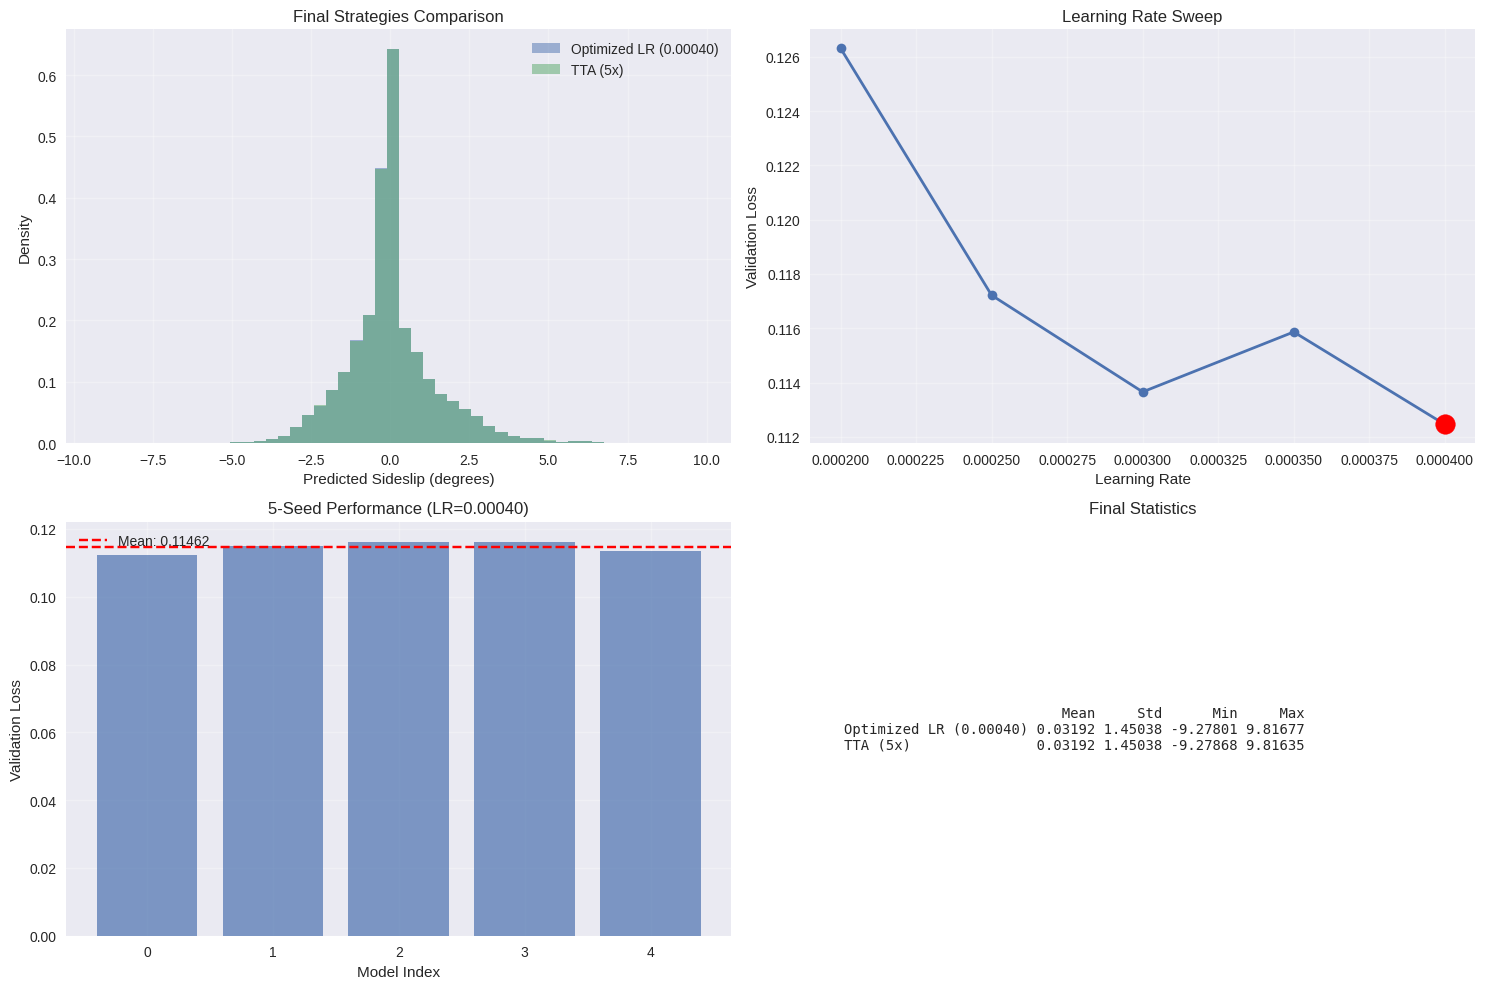

In [11]:
# Compare all strategies
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

strategies = {
    f'Optimized LR ({BEST_LR:.5f})': ensemble_best_lr,
    f'TTA ({NUM_AUGMENTATIONS}x)': tta_ensemble,
}

# Plot 1: Distributions
ax = axes[0, 0]
for name, preds in strategies.items():
    ax.hist(preds, bins=50, alpha=0.5, label=name, density=True)
ax.set_xlabel('Predicted Sideslip (degrees)')
ax.set_ylabel('Density')
ax.set_title('Final Strategies Comparison')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: LR sweep results
ax = axes[0, 1]
ax.plot([r['lr'] for r in lr_results], [r['val_loss'] for r in lr_results], 'o-', linewidth=2)
ax.scatter([BEST_LR], [lr_df.iloc[0]['val_loss']], color='red', s=200, zorder=5)
ax.set_xlabel('Learning Rate')
ax.set_ylabel('Validation Loss')
ax.set_title('Learning Rate Sweep')
ax.grid(True, alpha=0.3)

# Plot 3: Val loss comparison
ax = axes[1, 0]
ax.bar(range(len(val_losses_best_lr)), val_losses_best_lr, alpha=0.7)
ax.axhline(y=np.mean(val_losses_best_lr), color='r', linestyle='--', 
           label=f'Mean: {np.mean(val_losses_best_lr):.5f}')
ax.set_xlabel('Model Index')
ax.set_ylabel('Validation Loss')
ax.set_title(f'5-Seed Performance (LR={BEST_LR:.5f})')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: Statistics
ax = axes[1, 1]
stats_data = []
for name, preds in strategies.items():
    stats_data.append([preds.mean(), preds.std(), preds.min(), preds.max()])
stats_df = pd.DataFrame(stats_data, 
                        columns=['Mean', 'Std', 'Min', 'Max'],
                        index=list(strategies.keys()))
ax.text(0.05, 0.5, stats_df.to_string(float_format='%.5f'), 
        transform=ax.transAxes, 
        fontsize=10, 
        verticalalignment='center',
        family='monospace')
ax.axis('off')
ax.set_title('Final Statistics')

plt.tight_layout()
plt.show()